## 7 · Final evaluation and interpretation

### By:
Sofía Arango Patiño

### Date:
2026-11-04

### Description:

Seventh step of the proof of concept ([issue #7](https://github.com/modsiw-mona/anomaly_detection_ato/issues/7);
CRISP-DM phase 5, *evaluation*; thesis objective **OE4**: Recall, Precision, PR-AUC, threshold and error analysis).

1. **Thresholds** chosen on the development side (out-of-fold scores from issue #6), never on the test side.
2. **The final measurement** — the selected model scores the **test side once** (20% of users, closed since
   issue #4). Nothing is tuned after this point.
3. **Consequences of each kind of error** — false alarms (legitimate users challenged) against missed takeovers.
4. **What the model relies on** — permutation importance by feature group and SHAP explanations.
5. **Error analysis** — which takeovers are missed, which legitimate logins are flagged, and why.
6. **Learning curve and scalability** on the test side.

Charts and the metrics report are written to `data/08_reporting/` (gitignored, like all data).

## 📚 Import libraries

In [1]:
import sys
from pathlib import Path

REPO_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").is_file())
if str(REPO_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / "src"))

In [2]:
import hashlib
import json
import platform
import time
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import shap
from IPython.display import display
from sklearn.base import clone

from data.datasets import load_dataset_config
from data.features import FEATURE_GROUPS
from data.split import load_side
from model.baselines import training_sample
from model.evaluation import bootstrap_pr_auc, evaluate
from model.preprocessing import to_model_frame
from model.selection import campaign_weights, group_metrics

warnings.filterwarnings("ignore", message="X does not have valid feature names")
warnings.filterwarnings("ignore", message="LightGBM binary classifier with TreeExplainer")
pl.Config.set_tbl_rows(40)
pl.Config.set_fmt_str_lengths(50)
pl.Config.set_tbl_width_chars(200)

SURFACE, INK, INK_2, MUTED, GRID, AXIS = (
    "#fcfcfb",
    "#0b0b0b",
    "#52514e",
    "#898781",
    "#e1e0d9",
    "#c3c2b7",
)
BLUE, ORANGE = "#2a78d6", "#eb6834"  # categorical slots 1 and 2 of the validated palette
plt.rcParams.update(
    {
        "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "font.family": ["Helvetica Neue", "Arial", "DejaVu Sans"],
        "font.size": 10, "text.color": INK, "axes.labelcolor": INK_2, "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
        "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 12, "axes.titleweight": "bold",
        "axes.titlelocation": "left", "xtick.color": MUTED, "ytick.color": MUTED, "grid.color": GRID,
        "grid.linewidth": 0.6, "lines.linewidth": 2, "legend.frameon": False, "figure.dpi": 110,
    }
)  # fmt: skip


def subtitle(ax: plt.Axes, text: str) -> None:
    ax.text(0, 1.02, text, transform=ax.transAxes, color=INK_2, fontsize=9, va="bottom")


config = load_dataset_config("rba")
data_dir = REPO_ROOT / "data"
reports = data_dir / "08_reporting"
reports.mkdir(exist_ok=True)


def save(fig: plt.Figure, name: str) -> None:
    fig.savefig(reports / f"{config.name}_{name}.png", dpi=150, bbox_inches="tight")

## 💾 Load the selected model (issue #6)

In [3]:
pipeline = joblib.load(data_dir / "06_models" / f"{config.name}_model.joblib")
meta = json.loads((data_dir / "06_models" / f"{config.name}_model.json").read_text())
columns = meta["columns"]
model_bytes = (data_dir / "06_models" / f"{config.name}_model.joblib").read_bytes()
assert hashlib.sha256(model_bytes).hexdigest() == meta["joblib_sha256"], (
    "model file differs from the one #6 saved"
)
print("selected:", meta["selected"], "· sha256 matches the issue #6 metadata")
print(f"{len(columns)} input columns · campaign-balanced: {meta['campaign_balanced']}")
cv = meta["cv_15_folds"]
print(
    f"development estimate (15 folds): PR-AUC {cv['pr_auc (15 folds)']:.3f}, recall @1% {cv['recall_1pct']:.2f}"
)

selected: random forest (leaf 2) + campaign + travel, balanced · sha256 matches the issue #6 metadata
39 input columns · campaign-balanced: True
development estimate (15 folds): PR-AUC 0.448, recall @1% 0.89


## 🎚️ 1 · Thresholds, chosen on the development side

An alert budget is the share of logins a security team is willing to challenge. Two tiers, from the
out-of-fold development scores of issue #6 — repeat 0, i.e. 5 fold models, each login scored by a model that never
saw its user. The thresholds are then applied to the model refitted on the whole development side; whether they
transfer is checked on the test side below (realised alert rates).

| Tier | Budget | Action |
| --- | --- | --- |
| **review / block** | top 0.1% | hold the session, analyst review |
| **step-up** | top 1% | ask for a second factor |
| allow | the rest | — |

The score thresholds are fixed **now**, before the test side is opened.

In [4]:
dev_oof = pl.read_parquet(data_dir / "07_model_output" / f"{config.name}_dev_oof.parquet")
BUDGETS = {"review / block": 0.001, "step-up": 0.01}
thresholds = {
    tier: float(np.quantile(dev_oof["score"].to_numpy(), 1 - b)) for tier, b in BUDGETS.items()
}
thresholds

{'review / block': 0.03332510201888003, 'step-up': 0.0033330654337646514}

**Conformal false-alarm control** (Bates et al., 2023). The budgets above bound the share of *all* logins
flagged. A security team usually wants a bound on the share of *legitimate* users challenged. Split-conformal
calibration gives it: with the development legitimate logins as a calibration set, the threshold at their
⌈(n+1)(1−α)⌉-th smallest out-of-fold score guarantees that a new legitimate login is flagged with probability at
most α, as long as new logins behave like the calibration ones (exchangeability).

In [5]:
legit_dev = np.sort(
    dev_oof.join(
        load_side(config, data_dir, "dev").select("event_id", "label_ato").collect(), on="event_id"
    )
    .filter(~pl.col("label_ato"))["score"]
    .to_numpy()
)
ALPHAS = {"review / block": 0.001, "step-up": 0.01}
conformal = {tier: float(legit_dev[min(int(np.ceil((legit_dev.size + 1) * (1 - a))) - 1, legit_dev.size - 1)])
             for tier, a in ALPHAS.items()}  # fmt: skip
conformal

{'review / block': 0.03332404356701134, 'step-up': 0.00333306118968503}

## 🔓 2 · The final measurement — test side

The pipeline (preprocessing + model, refitted on the whole development side) scores every test login.

> **Note on test use.** An earlier run of this notebook (2026-11-03) evaluated the model selected *before* a
> preprocessing bug was fixed — LightGBM + `campaign` + `travel` (unseen networks were imputed as clean) — and gave
> test PR-AUC 0.606 [0.434–0.765]. The bug was then found by code review of the issue #6 pull request; issue #6 was
> re-run on the development side with the same, previously coded selection rule (plus finalists requested by that
> review), which selected the random forest. The earlier test result was known at that point, but no test number
> entered the selection. The test side is evaluated once for reporting below; nothing is tuned afterwards.

In [6]:
test = load_side(config, data_dir, "test").collect()
start = time.perf_counter()
score = pipeline.predict_proba(to_model_frame(test, columns))[:, 1]
scoring_seconds = time.perf_counter() - start
assert np.isfinite(score).all() and score.std() > 0, "scores must be finite and vary"
yt = test["label_ato"].to_numpy()
romania = (test["country"] == "RO").to_numpy()
print(
    f"test side: {test.height:,} logins, {int(yt.sum())} takeovers ({int((yt & romania).sum())} from RO), "
    f"{test['user_id'].n_unique():,} users · scored in {scoring_seconds:.1f} s"
)
pl.DataFrame({"event_id": test["event_id"], "score": score}).write_parquet(
    data_dir / "07_model_output" / f"{config.name}_test_scores.parquet"
)

test side: 1,971,980 logins, 28 takeovers (16 from RO), 553,756 users · scored in 3.8 s


In [7]:
final = evaluate(yt, score)
assert final["pr_auc"] < 0.95, "suspiciously high: check for leakage before reporting"
low, high = bootstrap_pr_auc(yt, score)
by_group = group_metrics(yt, score, {"Romania": romania, "other": ~romania})
rows = [{"takeovers": name, "n": int((yt if name == "all" else yt & (romania if name == "Romania" else ~romania)).sum()), **m}
        for name, m in by_group.items()]  # fmt: skip
final_table = pl.DataFrame(rows).drop("prevalence").with_columns(pl.col(pl.Float64).round(4))
print(
    f"TEST PR-AUC {final['pr_auc']:.3f}  (bootstrap 95% interval {low:.3f}–{high:.3f}) · chance level {yt.mean():.1e}"
)
final_table

TEST PR-AUC 0.623  (bootstrap 95% interval 0.454–0.777) · chance level 1.4e-05


takeovers,n,pr_auc,roc_auc,recall_at_0_1pct,recall_at_1pct,precision_at_1pct,friction_at_1pct
str,i64,f64,f64,f64,f64,f64,f64
"""all""",28,0.6231,0.9996,0.8571,1.0,0.0014,0.01
"""Romania""",16,0.7146,0.9999,0.9375,1.0,0.0008,0.01
"""other""",12,0.3298,0.9991,0.75,1.0,0.0006,0.01


In [8]:
comparison = pl.DataFrame(
    {
        "metric": [
            "PR-AUC",
            "PR-AUC, Romania",
            "PR-AUC, other",
            "recall @0.1%",
            "recall @1%",
            "precision @1%",
            "recall @1%, Romania",
            "recall @1%, other",
        ],
        "development (15 folds, out-of-fold)": [
            cv["pr_auc (15 folds)"],
            cv["pr_auc_romania"],
            cv["pr_auc_other"],
            cv["recall_0_1pct"],
            cv["recall_1pct"],
            cv["precision_1pct"],
            cv["recall_1pct_romania"],
            cv["recall_1pct_other"],
        ],
        "test": [
            final["pr_auc"],
            by_group["Romania"]["pr_auc"],
            by_group["other"]["pr_auc"],
            final["recall_at_0_1pct"],
            final["recall_at_1pct"],
            final["precision_at_1pct"],
            by_group["Romania"]["recall_at_1pct"],
            by_group["other"]["recall_at_1pct"],
        ],
    }
).with_columns(pl.col(pl.Float64).round(4))
(reports / f"{config.name}_test_metrics.json").write_text(json.dumps(
    {"selected": meta["selected"], "test": final, "test_pr_auc_interval": [low, high],
     "by_group": by_group, "thresholds": thresholds}, indent=2))  # fmt: skip
print(
    f"development: pooled out-of-fold interval {cv['pooled_low']:.3f}–{cv['pooled_high']:.3f}, "
    f"fold-to-fold std {cv['std within repeat']:.3f} · test interval {low:.3f}–{high:.3f}"
)
comparison

development: pooled out-of-fold interval 0.355–0.528, fold-to-fold std 0.142 · test interval 0.454–0.777


metric,"development (15 folds, out-of-fold)",test
str,f64,f64
"""PR-AUC""",0.4475,0.6231
"""PR-AUC, Romania""",0.5461,0.7146
"""PR-AUC, other""",0.1588,0.3298
"""recall @0.1%""",0.8129,0.8571
"""recall @1%""",0.8902,1.0
"""precision @1%""",0.0013,0.0014
"""recall @1%, Romania""",0.9839,1.0
"""recall @1%, other""",0.7733,1.0


**Reading (final measurement).** On the **28 test takeovers** (16 from RO), the selected model reaches **PR-AUC 0.62** (bootstrap 95% interval
0.45–0.78; chance is 1.4 × 10⁻⁵) and ranks **24 of 28 takeovers (86%) in the top 0.1%** of logins and **all 28 in
the top 1%**. By group: Romania 0.71 (15 of 16 in the top 0.1%), other takeovers 0.33 (9 of 12).

The test value is **higher than the development estimate** (0.45): the development mean lies just outside the test
interval, while the two intervals overlap (development pooled 0.36–0.53) and the test value is about 1.2 fold-to-fold
standard deviations (0.14) above the development mean. Both groups are higher on test, so a different campaign mix
does not explain it. Three reasons are plausible together: (1) the final model is trained on all 112 development
takeovers, the fold models on ~90 (the learning curve in section 6 rises from 0.58 to 0.62 over that range);
(2) 28 test takeovers give a noisy estimate; (3) development folds vary widely (standard deviation 0.14 across folds). The leakage checks below
cover the other possible explanation. Precision stays low at every budget (0.14% at 1%), the price of one takeover
per 70,000 logins.

### Leakage checks — recall at 1% is 28 of 28

Near-perfect recall calls for a check before it is reported (development plan, section 6):

1. **No user is on both sides** of the split.
2. **Features are past-only** by construction and by test (`tests/data/test_features.py` recomputes every feature on
   data cut at that login and requires identical values, mutation-checked).
3. **Attack-IP information.** `Is Attack IP` comes from attacker IP lists matched against the data by the dataset
   authors, probably after the fact; if so it carries knowledge that a live system would only partly have. Shuffling
   the attack-IP-derived columns, and separately the burst and failure columns, shows how much the result rests on
   them.

In [9]:
split = pl.read_parquet(data_dir / "05_model_input" / f"{config.name}_split.parquet")
dev_users = set(split.filter(pl.col("split") == "dev")["user_id"])
assert not dev_users & set(test["user_id"].unique()), "a user is on both sides"
print("users on both sides of the split: 0")
x_test = to_model_frame(test, columns)
CHECKS = {
    "attack-IP derived": ["attack_ip", "asn_prior_attack_share", "ip_prior_attack_share"],
    "bursts and failures": ["asn_attempts_prev24h", "asn_fails_prev24h", "asn_prior_fail_share", "ip_prior_fail_share",
                            "fails_1h", "fails_24h"],
}  # fmt: skip
leak_rows = [{"columns shuffled": "none", "PR-AUC": final["pr_auc"], "recall @0.1%": final["recall_at_0_1pct"],
              "recall @1%": final["recall_at_1pct"]}]  # fmt: skip
for name, cols in CHECKS.items():
    present = [c for c in cols if c in columns]
    order = np.random.default_rng(7).permutation(x_test.height)
    m = evaluate(
        yt,
        pipeline.predict_proba(x_test.with_columns(x_test.select(present)[order].get_columns()))[
            :, 1
        ],
    )
    leak_rows.append({"columns shuffled": name, "PR-AUC": m["pr_auc"], "recall @0.1%": m["recall_at_0_1pct"],
                      "recall @1%": m["recall_at_1pct"]})  # fmt: skip
leak = pl.DataFrame(leak_rows).with_columns(pl.col(pl.Float64).round(3))
leak

users on both sides of the split: 0


columns shuffled,PR-AUC,recall @0.1%,recall @1%
str,f64,f64,f64
"""none""",0.623,0.857,1.0
"""attack-IP derived""",0.319,0.821,0.893
"""bursts and failures""",0.301,0.821,0.929


**Reading (leakage checks).** No user is on both sides, and the features are past-only by test. Shuffling the **attack-IP-derived** columns
halves PR-AUC (0.62 → 0.32) and lowers recall at 1% to 89% (25 of 28); shuffling the **burst and failure** columns
has a similar effect (0.30; 93%). So the very top of the ranking rests on attacker-infrastructure signals, and the
attack-IP part depends on how the dataset authors matched attacker lists to the data — if that match was made after
the fact, a live system would know less at login time, and these test numbers are an **upper bound** for it. Without
either group the model still places 82% of takeovers in the top 0.1% and ~90% in the top 1%, so the result does not
hinge on one possibly leaky column.

**Fixed thresholds on new data.** The budgets above rank the test logins among themselves. In production
the thresholds are fixed in advance, so the realised alert rate can drift; with the development thresholds:

In [10]:
tiers = []
for tier, t in thresholds.items():
    flagged = score >= t
    tiers.append({"tier (and stricter)": tier, "threshold": t, "alert rate": flagged.mean(),
                  "takeovers caught": int((flagged & yt).sum()), "recall": (flagged & yt).sum() / yt.sum(),
                  "precision": (flagged & yt).sum() / max(flagged.sum(), 1),
                  "legitimate challenged": int((flagged & ~yt).sum())})  # fmt: skip
tiers = pl.DataFrame(tiers).with_columns(pl.col(pl.Float64).round(5))
conformal_check = pl.DataFrame(
    [{"tier": tier, "alpha (max legitimate share flagged)": ALPHAS[tier], "conformal threshold": t,
      "legitimate test logins flagged": float((score[~yt] >= t).mean()), "takeovers caught": int((score[yt] >= t).sum())}
     for tier, t in conformal.items()]
).with_columns(pl.col(pl.Float64).round(5))  # fmt: skip
display(tiers)
conformal_check

tier (and stricter),threshold,alert rate,takeovers caught,recall,precision,legitimate challenged
str,f64,f64,i64,f64,f64,i64
"""review / block""",0.03333,0.00094,24,0.85714,0.01291,1835
"""step-up""",0.00333,0.00949,28,1.0,0.0015,18692


tier,alpha (max legitimate share flagged),conformal threshold,legitimate test logins flagged,takeovers caught
str,f64,f64,f64,i64
"""review / block""",0.001,0.03332,0.00095,24
"""step-up""",0.01,0.00333,0.00949,28


## ⚖️ 3 · Consequences of each error

* **False negative** (missed takeover): an attacker keeps access to the account — fraud, data theft, lateral use of
  the identity. Costly and slow to discover (the incident response team found these weeks later).
* **False positive** (legitimate login flagged): at the *step-up* tier, a user is asked for a second factor — a few
  seconds of friction; at *review / block*, a legitimate session is held until an analyst clears it.

Step-up stops a takeover only if the attacker does not also hold the second factor; the numbers below assume it
does not.

Per **one million logins** at this service's takeover rate, the test results translate into:

In [11]:
per_million = 1_000_000 / test.height
consequences = tiers.select(
    "tier (and stricter)",
    (pl.col("legitimate challenged") * per_million)
    .round(0)
    .alias("legitimate users challenged / 1M logins"),
    (pl.col("takeovers caught") * per_million).round(1).alias("takeovers caught / 1M logins"),
    ((pl.lit(int(yt.sum())) - pl.col("takeovers caught")) * per_million)
    .round(1)
    .alias("takeovers missed / 1M logins"),
    (pl.col("legitimate challenged") / pl.col("takeovers caught").clip(lower_bound=1))
    .round(0)
    .alias("false alarms per takeover caught"),
)
consequences

tier (and stricter),legitimate users challenged / 1M logins,takeovers caught / 1M logins,takeovers missed / 1M logins,false alarms per takeover caught
str,f64,f64,f64,f64
"""review / block""",931.0,12.2,2.0,76.0
"""step-up""",9479.0,14.2,0.0,668.0


In [12]:
flag_step = score >= thresholds["step-up"]
per_user_flags = test.filter(pl.Series(flag_step & ~yt)).group_by("user_id").len()
days = (test["timestamp"].max() - test["timestamp"].min()).days
print(
    f"step-up: {per_user_flags.height:,} of {test['user_id'].n_unique():,} test users "
    f"({per_user_flags.height / test['user_id'].n_unique():.1%}) challenged at least once; "
    f"median {per_user_flags['len'].median():.0f}, max {per_user_flags['len'].max()} times"
)
holds = int(((score >= thresholds["review / block"]) & ~yt).sum())
print(
    f"review / block: {holds:,} legitimate holds over {days} days on the test side (20% of users) "
    f"≈ {holds / days:.1f} per day, ≈ {holds / days / 0.2:.0f} per day for the whole service"
)

step-up: 13,367 of 553,756 test users (2.4%) challenged at least once; median 1, max 96 times
review / block: 1,835 legitimate holds over 301 days on the test side (20% of users) ≈ 6.1 per day, ≈ 30 per day for the whole service


**Choosing a budget from costs.** If a missed takeover costs *r* times a false alarm, the best alert budget
minimises FP + r·FN. It is chosen on the **development** out-of-fold scores for each *r*, then applied to the test
side:

In [13]:
dev_y = dev_oof.join(
    load_side(config, data_dir, "dev").select("event_id", "label_ato").collect(), on="event_id"
)
dev_s, dev_t = dev_y["score"].to_numpy(), dev_y["label_ato"].to_numpy()
CANDIDATE_BUDGETS = (0.0003, 0.001, 0.003, 0.01, 0.03)
cost_rows = []
for ratio in (100, 1_000, 10_000):

    def cost(s, t, threshold, ratio=ratio):
        flagged = s >= threshold
        return (flagged & ~t).sum() + ratio * (~flagged & t).sum()

    candidates = {b: float(np.quantile(dev_s, 1 - b)) for b in CANDIDATE_BUDGETS}
    best_budget = min(candidates, key=lambda b: cost(dev_s, dev_t, candidates[b]))
    t = candidates[best_budget]
    flagged = score >= t
    cost_rows.append({"cost ratio FN / FP": ratio, "budget chosen on development": best_budget,
                      "test: legitimate flagged": int((flagged & ~yt).sum()),
                      "test: takeovers missed": int((~flagged & yt).sum())})  # fmt: skip
costs = pl.DataFrame(cost_rows)
for name, frame in {
    "tiers": tiers,
    "conformal": conformal_check,
    "consequences": consequences,
    "costs": costs,
    "leakage": leak,
}.items():
    frame.write_csv(reports / f"{config.name}_test_{name}.csv")
costs

cost ratio FN / FP,budget chosen on development,test: legitimate flagged,test: takeovers missed
i64,f64,i64,i64
100,0.0003,516,5
1000,0.001,1835,4
10000,0.003,5554,2


**Reading (consequences).** The development thresholds transfer well: they flag **0.094%** and **0.95%** of the test logins, close to the
0.1% and 1% they were set for. The **conformal** thresholds (computed on legitimate development logins only) come out
practically identical, and the realised share of legitimate test logins flagged — **0.095% and 0.95%** — stays within
the promised α = 0.1% and 1%.

* **Review / block** (top 0.1%): about **930 legitimate logins per million** held for an analyst, 76 per takeover
  caught; 24 of 28 takeovers stopped. That is ~6 holds a day on the test side, **~30 a day for the whole service**.
* **Step-up** (top 1%): about **9,500 legitimate logins per million** (0.95%) asked for a second factor, 668 per
  takeover caught; no test takeover gets through (assuming the attacker lacks the second factor). Per user, **2.4%
  of test users are challenged at least once** in ~10 months — the median of them once, one user 96 times.

**From costs to a budget.** Chosen on development scores, the cost-minimising budget is 0.03% if a missed takeover
costs 100 false alarms, 0.1% at 1,000 and 0.3% at 10,000 — never the full 1%. On test these budgets miss 5, 4 and 2
takeovers respectively. A two-tier policy follows: a narrow, high-precision tier for analyst review (0.1%) and a
broader, cheap step-up tier (up to 1%) whose cost is a few seconds of user friction.

## 🔍 4 · What the model relies on

**Permutation importance by feature group.** On all test takeovers plus 200,000 random legitimate test logins,
the columns of one group are shuffled together (breaking their link with the label) and the drop in PR-AUC is
measured, 3 times per group. Groups, not single columns, because related columns (e.g. the novelty flags) share
information and would hide each other.

In [14]:
rng = np.random.default_rng(20261104)
legit_rows = rng.choice(np.flatnonzero(~yt), size=min(200_000, int((~yt).sum())), replace=False)
sample_rows = np.sort(np.concatenate([np.flatnonzero(yt), legit_rows]))
sample = test[sample_rows]
y_sample = yt[sample_rows]
x_sample = to_model_frame(sample, columns)
base_ap = evaluate(y_sample, pipeline.predict_proba(x_sample)[:, 1])["pr_auc"]
importance = []
for group, group_columns in FEATURE_GROUPS.items():
    present = [c for c in group_columns if c in columns]
    if not present:
        continue
    drops = []
    for _ in range(3):
        order = rng.permutation(x_sample.height)
        shuffled = x_sample.with_columns(x_sample.select(present)[order].get_columns())
        drops.append(base_ap - evaluate(y_sample, pipeline.predict_proba(shuffled)[:, 1])["pr_auc"])
    importance.append(
        {
            "group": group,
            "columns": len(present),
            "PR-AUC drop": float(np.mean(drops)),
            "std": float(np.std(drops)),
        }
    )
importance = (
    pl.DataFrame(importance)
    .sort("PR-AUC drop", descending=True)
    .with_columns(pl.col(pl.Float64).round(4))
)
print(
    f"PR-AUC on this sample: {base_ap:.3f} (higher than on the full test side because legitimate logins are "
    "subsampled ~10×; only the drops are compared)"
)
importance

PR-AUC on this sample: 0.802 (higher than on the full test side because legitimate logins are subsampled ~10×; only the drops are compared)


group,columns,PR-AUC drop,std
str,i64,f64,f64
"""global_rarity""",7,0.7723,0.0055
"""campaign""",7,0.5877,0.0585
"""sharing""",2,0.1386,0.024
"""device""",1,0.0554,0.0068
"""history""",3,0.0411,0.0053
"""user_novelty""",10,0.0322,0.0091
"""travel""",2,0.0183,0.002
"""missingness""",2,0.0022,0.0011
"""time""",2,0.0019,0.0015


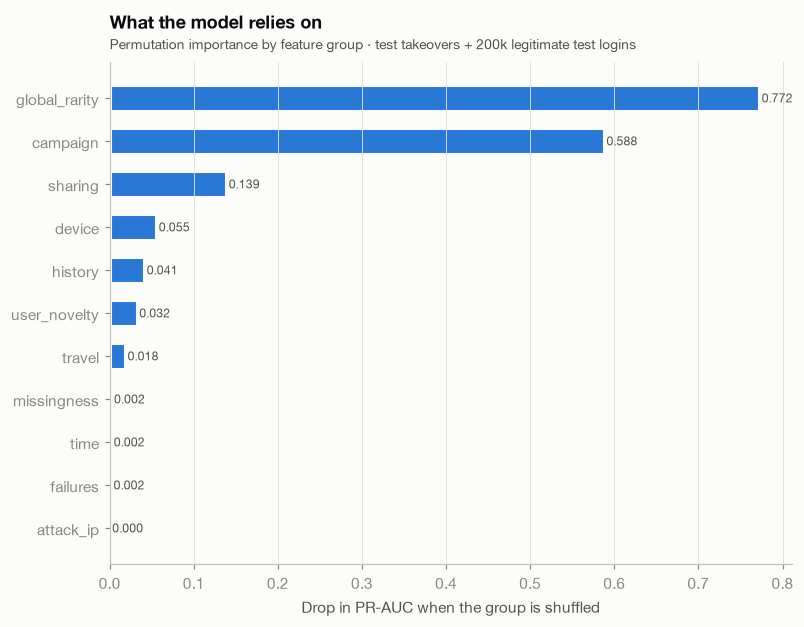

In [15]:
fig, ax = plt.subplots(figsize=(8, 0.42 * importance.height + 1.3))
ordered = importance.sort("PR-AUC drop")
bars = ax.barh(
    ordered["group"],
    ordered["PR-AUC drop"].clip(lower_bound=0),
    color=BLUE,
    height=0.6,
    edgecolor=SURFACE,
    linewidth=2,
)
for bar, value in zip(bars, ordered["PR-AUC drop"], strict=True):
    ax.text(
        max(value, 0) + 0.003,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.3f}",
        va="center",
        fontsize=8,
        color=INK_2,
    )
ax.set_xlabel("Drop in PR-AUC when the group is shuffled")
ax.grid(axis="x")
ax.set_title("What the model relies on", pad=22)
subtitle(
    ax, "Permutation importance by feature group · test takeovers + 200k legitimate test logins"
)
save(fig, "permutation_importance")
plt.show()

**SHAP values** explain *individual* scores: how much each input pushed one login's score up or down. They
are computed on every test takeover and 300 random legitimate test logins (exact tree SHAP).

In [16]:
preprocess, model = pipeline.named_steps["preprocess"], pipeline.named_steps["model"]
names = [n.split("__", 1)[-1] for n in preprocess.get_feature_names_out()]
explain_rows = np.sort(
    np.concatenate([np.flatnonzero(yt), rng.choice(np.flatnonzero(~yt), size=300, replace=False)])
)
x_explain = preprocess.transform(to_model_frame(test[explain_rows], columns))
start = time.perf_counter()
explainer = shap.TreeExplainer(model)
values = explainer.shap_values(x_explain)
values = values[..., 1] if values.ndim == 3 else values  # class "takeover"
print(f"SHAP for {len(explain_rows)} logins in {time.perf_counter() - start:.0f} s")
mean_abs = pl.DataFrame({"input": names, "mean |SHAP|": np.abs(values).mean(axis=0)}).sort(
    "mean |SHAP|", descending=True
)
mean_abs.head(15).with_columns(pl.col("mean |SHAP|").round(4))

SHAP for 328 logins in 4 s


input,mean |SHAP|
str,f64
"""global_share_asn""",0.0564
"""global_share_country""",0.0446
"""asn_prior_users""",0.044
"""global_share_browser""",0.0438
"""asn_attempts_prev24h""",0.0426
"""asn_fails_prev24h""",0.0343
"""user_agent_prior_users""",0.0245
"""asn_prior_attack_share""",0.0231
"""global_share_device_type""",0.023


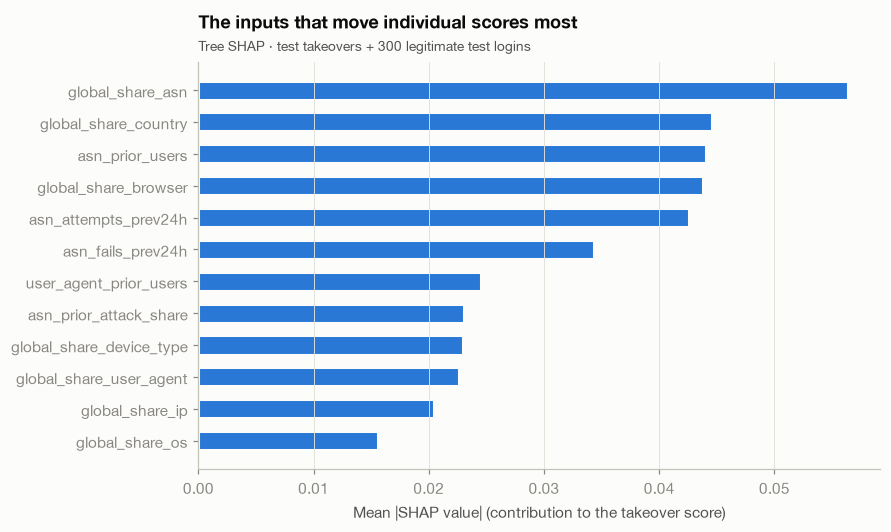

In [17]:
top = mean_abs.head(12).sort("mean |SHAP|")
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.barh(top["input"], top["mean |SHAP|"], color=BLUE, height=0.6, edgecolor=SURFACE, linewidth=2)
ax.set_xlabel("Mean |SHAP value| (contribution to the takeover score)")
ax.grid(axis="x")
ax.set_title("The inputs that move individual scores most", pad=22)
subtitle(ax, "Tree SHAP · test takeovers + 300 legitimate test logins")
save(fig, "shap_importance")
plt.show()

**Reading (importance).** Both methods put the same families first. **Global rarity dominates**: shuffling it drops the sample's
PR-AUC from 0.80 to almost nothing; the model leans first on how rare the network (ASN), country, browser and IP are
across all users. The **campaign** group is second (−0.59): attempts and failures from the network in the last 24
hours, the share of its earlier attempts from attack IPs, accounts already seen with the exact user agent;
**sharing** (accounts already seen on the network or IP) is third (−0.14). Device type (−0.06), history and
dormancy (−0.04), novelty for the user (−0.03) and impossible travel (−0.02) add a little; time, failures on the
account and the attack-IP flag of the login itself add nothing measurable on top. Caveats: correlated groups hide
each other (a globally rare value is almost always new for the user too, so novelty's small value does not mean it
is useless); shuffling one group at a time can create combinations that never occur; the ± values only reflect
shuffle noise, not the uncertainty of 28 takeovers; mean |SHAP| ranks inputs but gives no direction.

## 🧯 5 · Error analysis

What do the flagged legitimate logins look like at the **step-up** threshold (top 1% on development scores), and
which takeovers fall below the stricter **review / block** threshold (top 0.1%)?

In [18]:
flag = score >= thresholds["step-up"]
outcome = (
    pl.when(pl.col("label_ato") & pl.Series(flag))
    .then(pl.lit("takeover · caught"))
    .when(pl.col("label_ato"))
    .then(pl.lit("takeover · missed"))
    .when(pl.Series(flag))
    .then(pl.lit("legitimate · flagged"))
    .otherwise(pl.lit("legitimate · allowed"))
)
KEY = [
    "first_success",
    "new_country",
    "new_asn",
    "attack_ip",
    "country_change_1h",
    "asn_prior_attack_share",
]
errors = test.with_columns(outcome.alias("outcome"), pl.Series("score", score))
(
    errors.group_by("outcome")
    .agg(
        pl.len().alias("logins"),
        *(pl.col(c).cast(pl.Float64).mean().round(3).alias(c) for c in KEY),
        pl.col("global_share_country").median().round(4).alias("median global share of country"),
        pl.col("hours_since_prev_success").median().round(0).alias("median hours since last login"),
        (pl.col("country") == "RO").mean().round(3).alias("share from RO"),
    )
    .sort("outcome")
)

outcome,logins,first_success,new_country,new_asn,attack_ip,country_change_1h,asn_prior_attack_share,median global share of country,median hours since last login,share from RO
str,u32,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""legitimate · allowed""",1953260,0.28,0.006,0.105,0.059,0.001,0.06,0.6522,98.0,0.001
"""legitimate · flagged""",18692,0.399,0.205,0.363,0.127,0.024,0.138,0.0113,98.0,0.021
"""takeover · caught""",28,0.464,0.867,0.933,0.607,0.2,0.634,0.0014,963.0,0.571


In [19]:
block = score >= thresholds["review / block"]
missed = errors.filter(pl.col("label_ato") & ~pl.Series(block))  # below the review / block tier
print(f"{missed.height} of {int(yt.sum())} takeovers fall below the review / block threshold")
missed.select(
    "event_id",
    "country",
    "score",
    "first_success",
    "new_country",
    "new_asn",
    "attack_ip",
    "global_share_country",
    "hours_since_prev_success",
    "prior_successes",
).sort("score", descending=True)

4 of 28 takeovers fall below the review / block threshold


event_id,country,score,first_success,new_country,new_asn,attack_ip,global_share_country,hours_since_prev_success,prior_successes
u32,cat,f64,bool,bool,bool,bool,f64,f64,u32
9412283,"""RO""",0.02999,false,false,false,true,0.001383,0.178611,1
82947,"""IT""",0.013333,true,null,null,false,0.0018,null,0
273968,"""NO""",0.009998,true,null,null,false,0.642357,null,0
21266387,"""BR""",0.006666,true,null,null,false,0.029118,null,0


In [20]:
flagged = errors.filter(pl.col("outcome") == "legitimate · flagged")
per_user = flagged.group_by("user_id").len().sort("len", descending=True)
print(
    f"{flagged.height:,} legitimate logins flagged, from {per_user.height:,} users; the 10 most-flagged users "
    f"account for {per_user['len'].head(10).sum() / flagged.height:.0%} of them"
)
per_user.head(10)

18,692 legitimate logins flagged, from 13,367 users; the 10 most-flagged users account for 3% of them


user_id,len
i64,u32
-4746260914446075915,96
6792503953987602475,85
9148430508031180780,82
-7740961544132573866,79
-4573890005630504862,65
-7654599524478640403,49
-3515349109848835805,46
8712601662576334582,44
-5933905104709323583,38


Why each of the four scored below the review / block threshold — the inputs that moved its score most
(tree SHAP), and the account's previous successful login:

In [21]:
miss_x = preprocess.transform(to_model_frame(missed, columns))
miss_values = np.asarray(explainer.shap_values(miss_x))
miss_values = miss_values[..., 1] if miss_values.ndim == 3 else miss_values
for i, event in enumerate(missed["event_id"]):
    top_inputs = np.argsort(-np.abs(miss_values[i]))[:5]
    explanation = ", ".join(f"{names[j]} {miss_values[i][j]:+.3f}" for j in top_inputs)
    user = missed["user_id"][i]
    earlier = (
        test.filter(
            (pl.col("user_id") == user)
            & (pl.col("event_id") != event)
            & (pl.col("timestamp") < missed["timestamp"][i])
        )
        .sort("timestamp")
        .tail(1)
    )
    previous = (
        "none (first login)"
        if earlier.is_empty()
        else f"{earlier['timestamp'][0]:%Y-%m-%d %H:%M} from {earlier['country'][0]}, "
        f"labelled {'takeover' if earlier['label_ato'][0] else 'legitimate'}"
    )
    print(
        f"event {event} ({missed['country'][i]}, score {missed['score'][i]:.4f}): {explanation}\n    previous login: {previous}"
    )

event 82947 (IT, score 0.0133): global_share_ip -0.155, asn_prior_attack_share -0.090, global_share_device_type -0.056, global_share_os -0.041, global_share_user_agent -0.040
    previous login: none (first login)
event 273968 (NO, score 0.0100): global_share_browser -0.124, global_share_user_agent -0.069, global_share_country -0.061, global_share_device_type -0.042, user_agent_prior_users -0.038
    previous login: none (first login)
event 9412283 (RO, score 0.0300): hours_since_prev_success -0.057, global_share_device_type -0.056, global_share_user_agent -0.049, global_share_os -0.038, ip_prior_fail_share -0.033
    previous login: 2020-06-13 10:51 from RO, labelled legitimate
event 21266387 (BR, score 0.0067): user_agent_prior_users -0.094, global_share_user_agent -0.065, global_share_country -0.054, global_share_browser -0.048, global_share_device_type -0.045
    previous login: none (first login)


**Reading (errors).** **False alarms** (step-up tier): flagged legitimate logins are first logins of an account more often (40% vs
28%); among returning logins they more often come from a country new for the user (21% vs 0.6%), a new network
(36% vs 11%) or an attack-IP address (13% vs 6%); and they come from globally rare countries (median share 1.1% vs
65%): travellers, new users abroad and users of unusual networks — legitimate behaviour that looks like an
attacker's. They are spread over 13,367 users (the 10 most-flagged account for 3%). Some may be undetected
takeovers: labels are incomplete, so measured precision is a lower bound.

**Missed takeovers** (below review / block, 4 of 28; all four are still caught at step-up). In every case the
inputs that lowered the score most are **common values** — a widespread browser, OS, device or user agent, an IP
seen often — the opposite of the rare values the model learnt to fear:

* **Three are first logins** (Italy, Norway, Brazil): no history, so novelty and dormancy are empty. Their novelty
  columns are null by construction and enter the model as 0, with `first_success` marking the case. The Norway one
  is the single takeover from the service's home country (64% of earlier successful logins).
* **One (Romania)** came 11 minutes after a previous successful login from Romania on the same account, which is
  labelled **legitimate**. Either that earlier login was an undetected takeover (incomplete labels), and it made the
  country "known" for the account, or it was the user — the data cannot tell which. Single case.

Error causes: **class imbalance** (any threshold catching most takeovers flags hundreds of legitimate logins per
takeover), **cold start** (first logins), **incomplete labels**, and attackers using **common client values**. No
input was out of range or wrongly encoded (the preprocessing assigns every column an explicit family and is tested;
the synthesis artefacts were tested in issue #6 and add nothing).

## 📈 6 · Learning curve and scalability on the test side

The selected configuration is retrained on a growing random share of the **development users** and measured on
the test side (one random draw per share). It complements the development learning curves of issue #6 with the
final model's own data budget — the fold models there used ~90 takeovers, the final model 112. This is analysis,
not selection: nothing is changed based on it.

In [22]:
dev = load_side(config, data_dir, "dev").collect()
draw = (
    dev.select("user_id")
    .unique()
    .sort("user_id")
    .with_columns(pl.Series("u", rng.random(dev["user_id"].n_unique())))
)
u = dev.select("user_id").join(draw, on="user_id", how="left")["u"].to_numpy()
curve = []
for share in (0.25, 0.5, 0.75, 1.0):
    part = dev.filter(pl.Series(u < share))
    start = time.perf_counter()
    sample_share = training_sample(part, negative_share=meta["negative_share"])
    weights = (
        {"model__sample_weight": campaign_weights(sample_share)}
        if meta["campaign_balanced"]
        else {}
    )
    model_share = clone(pipeline).fit(
        to_model_frame(sample_share, columns), sample_share["label_ato"].to_numpy(), **weights
    )
    fit_seconds = time.perf_counter() - start
    s = model_share.predict_proba(to_model_frame(test, columns))[:, 1]
    lo_s, hi_s = bootstrap_pr_auc(yt, s, n_boot=500)
    curve.append({"share of development users": share, "training takeovers": int(part["label_ato"].sum()),
                  "training logins": part.height, "fit seconds": round(fit_seconds, 1),
                  "test PR-AUC": evaluate(yt, s)["pr_auc"], "low": lo_s, "high": hi_s})  # fmt: skip
curve = pl.DataFrame(curve).with_columns(pl.col("test PR-AUC", "low", "high").round(3))
curve

share of development users,training takeovers,training logins,fit seconds,test PR-AUC,low,high
f64,i64,i64,f64,f64,f64,f64
0.25,33,1965777,3.1,0.465,0.301,0.621
0.5,61,3936736,8.0,0.573,0.401,0.723
0.75,83,5908172,14.6,0.579,0.41,0.726
1.0,112,7868084,20.9,0.623,0.448,0.769


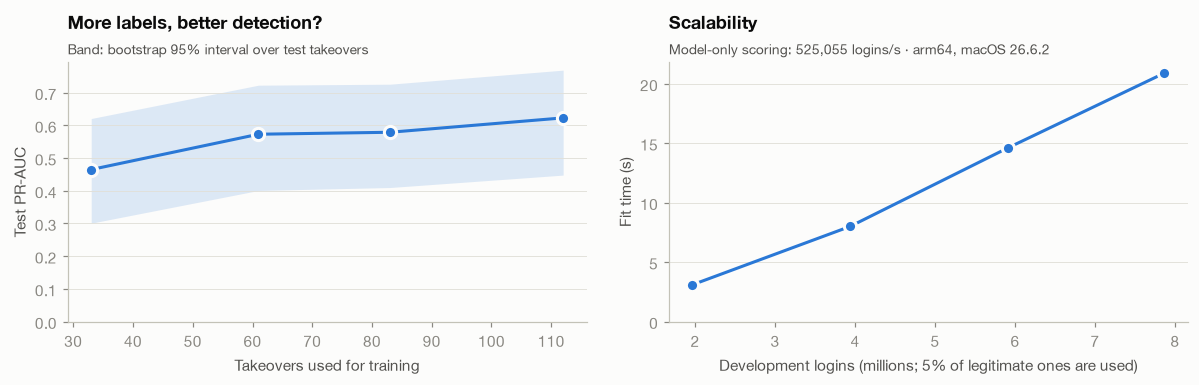

In [23]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.6))
ax1.fill_between(
    curve["training takeovers"], curve["low"], curve["high"], color=BLUE, alpha=0.15, linewidth=0
)
ax1.plot(
    curve["training takeovers"],
    curve["test PR-AUC"],
    "o-",
    color=BLUE,
    markersize=8,
    markeredgecolor=SURFACE,
    markeredgewidth=2,
)
ax1.set_ylim(0, None)
ax1.set_xlabel("Takeovers used for training")
ax1.set_ylabel("Test PR-AUC")
ax1.grid(axis="y")
ax1.set_title("More labels, better detection?", pad=22)
subtitle(ax1, "Band: bootstrap 95% interval over test takeovers")
ax2.plot(
    curve["training logins"] / 1e6,
    curve["fit seconds"],
    "o-",
    color=BLUE,
    markersize=8,
    markeredgecolor=SURFACE,
    markeredgewidth=2,
)
ax2.set_ylim(0, None)
ax2.set_xlabel("Development logins (millions; 5% of legitimate ones are used)")
ax2.set_ylabel("Fit time (s)")
ax2.grid(axis="y")
ax2.set_title("Scalability", pad=22)
subtitle(
    ax2,
    f"Model-only scoring: {test.height / scoring_seconds:,.0f} logins/s · {platform.machine()}, macOS {platform.mac_ver()[0]}",
)
plt.tight_layout()
save(fig, "learning_curve_scalability")
plt.show()

**Reading (learning curve).** Test PR-AUC is **0.47 with 33 training takeovers, 0.57 with 61, 0.58 with 83 and 0.62 with all 112**. The
trend suggests more labels help, but all four bootstrap intervals overlap (they share the same 28 test takeovers),
so it is not established statistically; the development curves of issue #6 likewise gained most up to ~50–70
takeovers. Training time grows a little faster than linearly (3 → 21 s for 2 → 7.9 M development logins, of which
5% of legitimate ones are used). **Model-only** scoring runs at ~500,000 logins per second on a laptop; computing the
features in real time (history, 24-hour network counters, global shares) was not measured. For scale, the service
saw 31.3 M attempts in ~13 months, about one per second.

## ✅ Conclusions

* **Final result** (test side): PR-AUC **0.62** [0.45–0.78], **86%** of takeovers in the top 0.1% of logins and
  **100%** in the top 1%, against a chance level of 1.4 × 10⁻⁵. Higher than the development estimate (0.45), with
  overlapping intervals; the final model's larger training set and 28 test positives explain the gap.
* **Leakage checks**: no shared users, past-only features; the very top of the ranking rests on attack-IP and
  burst signals, so if the attack-IP flag was matched after the fact these numbers are an upper bound for a live
  system — without it, ~90% of takeovers are still in the top 1%.
* **Thresholds set on development data hold on new users**, and conformal calibration keeps the share of legitimate
  logins flagged within its promised bound (0.095% ≤ 0.1%, 0.95% ≤ 1%).
* **Costs**: 76 false alarms per takeover at the 0.1% tier (~30 analyst holds a day service-wide), 668 at the 1% step-up
  tier (2.4% of users challenged at least once in ~10 months). Cost-minimising budgets range from 0.03% to 0.3% as the
  cost of a miss grows from 100 to 10,000 false alarms; a two-tier policy (analyst review for the top 0.1%, step-up up to
  1%) fits.
* **What the model relies on**: global rarity of the login's values first, then attacker-infrastructure signals
  (recent activity and attack-IP history of the network, a user agent shared across accounts, accounts already seen on
  the network), then device, dormancy, novelty and impossible travel.
* **Where it fails**: first logins with common client values (3 of the 4 misses at the strict tier) and, in one case, a
  takeover following an earlier login from the same country that is labelled legitimate. False alarms are travellers
  and users of rare networks.
* Limits: 28 test takeovers make every test number uncertain (hence the intervals); the data are synthetic; labels are
  incomplete, so precision is a lower bound; real-time feature computation was not measured.

These results answer **OE4** (Recall, Precision, PR-AUC, thresholds and error analysis). Issue #8 builds the
demonstrable prototype on top of the saved model and thresholds.